<a href="https://colab.research.google.com/github/NadinCantikaSari/Statistika_Revisi_Kel2/blob/main/AnalisisDeskriptifSupermartGrocery_REVISI_FINAL_Kelompok2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(135deg,#F6FAFC,#E5F3EF); border-left:7px solid #2A9D8F; padding:22px 24px; border-radius:12px;">
  <div style="color:#2A9D8F;font-size:13px;font-weight:700;letter-spacing:1px;">KELOMPOK 2 · STATISTIKA DESKRIPTIF · REVISI 2026</div>
  <h1 style="color:#17324D;line-height:1.35;">Analisis Deskriptif Tingkat Diskon, Nilai Penjualan, dan Profit pada Transaksi Retail Berdasarkan Kategori Produk</h1>
  <div style="color:#415466;line-height:1.7;">
  <b>Dataset:</b> Supermart Grocery Sales – Retail Analytics Dataset<br>
  <b>Anggota:</b> Rania Maisha Inaya · Dinda Zaskia Putri · Nadin Cantika Sari<br>
  <b>Pendekatan:</b> pemeriksaan data, statistika deskriptif, histogram, dan analisis deskriptif berdasarkan <i>Category</i>.
  </div>
</div>

**Petunjuk:** Jalankan sel berurutan dari atas ke bawah di Google Colab melalui **Runtime → Run all**. Saat diminta, unggah file Excel dataset kelompok 2. Gunakan worksheet **`Data_Cleaning`**. Output tabel dan grafik disertakan dalam notebook ini dari hasil eksekusi terhadap workbook yang dikirim.

**Cakupan revisi:** Bagian probabilitas empiris (Q3 Profit tinggi, tertil Discount, dan probabilitas bersyarat) dari versi lama dihapus dari alur utama agar sesuai dengan tiga rumusan masalah terbaru. Tidak ada pengujian statistik inferensial.

## Rumusan Masalah dan Tujuan Analisis

1. **RM 1 — Karakteristik data:** Bagaimana karakteristik Sales, Discount, dan Profit pada transaksi retail?
2. **RM 2 — Pola distribusi:** Bagaimana pola distribusi Sales, Discount, dan Profit pada transaksi retail berdasarkan histogram serta ukuran median dan standar deviasi?
3. **RM 3 — Perbandingan kategori:** Bagaimana perbandingan Sales, Discount, dan Profit secara deskriptif berdasarkan Category produk?

| Rumusan masalah | Metode / output notebook | Kesesuaian dengan laporan |
|:--|:--|:--|
| RM 1 | N, mean, median, standar deviasi, minimum, maksimum | BAB 4.3 |
| RM 2 | Histogram Sales, Discount, Profit; posisi mean dan median | BAB 4.4 |
| RM 3 | N, mean, median, standar deviasi per Category serta diagram batang mean | BAB 4.5 |

<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">1. Import Library dan Pengaturan Tampilan</h2>

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# ============================================================
# IDENTITAS VISUAL KELOMPOK 2
# Navy = utama, Teal = aksen, Gold = penekanan, Mint = latar lembut
# ============================================================
NAVY = '#17324D'
TEAL = '#2A9D8F'
GOLD = '#E9C46A'
MINT = '#DFF3EC'
BG = '#F7FAFC'
GRID = '#D9E2E8'
TEXT = '#334E68'

WARNA_VARIABEL = {
    'Sales': '#4D8FAC',
    'Discount': TEAL,
    'Profit': GOLD
}

WARNA_KATEGORI = {
    'Bakery': '#E9C46A',
    'Beverages': '#4D8FAC',
    'Eggs, Meat & Fish': '#2A9D8F',
    'Food Grains': '#7FA36B',
    'Fruits & Veggies': '#8C78A8',
    'Oil & Masala': '#D98E73',
    'Snacks': '#6F8FA6'
}

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'figure.facecolor': 'white',
    'axes.facecolor': BG,
    'axes.edgecolor': '#B8C5D1',
    'axes.labelcolor': TEXT,
    'axes.titlecolor': NAVY,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'xtick.color': TEXT,
    'ytick.color': TEXT,
    'text.color': TEXT,
    'font.size': 10,
    'grid.color': GRID,
    'grid.linestyle': '--',
    'grid.alpha': 0.55,
    'legend.frameon': False
})

def rapikan_axes(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, axis='y', zorder=0)
    return ax

def tampil_tabel(df_tabel, caption=None, format_dict=None):
    styler = (
        df_tabel.style
        .set_properties(**{
            'background-color': '#FFFFFF',
            'color': TEXT,
            'border-color': '#D9E2E8',
            'padding': '6px 8px'
        })
        .set_table_styles([
            {'selector': 'thead th',
             'props': [('background-color', NAVY),
                       ('color', 'white'),
                       ('font-weight', 'bold'),
                       ('border-color', NAVY),
                       ('padding', '7px 8px')]},
            {'selector': 'tbody tr:nth-child(even) td',
             'props': [('background-color', '#F4F9F7')]},
            {'selector': 'caption',
             'props': [('caption-side', 'top'),
                       ('color', NAVY),
                       ('font-weight', 'bold'),
                       ('font-size', '13px'),
                       ('padding-bottom', '8px')]}
        ])
    )
    if caption:
        styler = styler.set_caption(caption)
    if format_dict:
        styler = styler.format(format_dict)
    return styler

In [ ]:
# Helper menampilkan bilangan dengan format Indonesia untuk interpretasi teks.
def format_id(nilai, digit=2):
    return f'{nilai:,.{digit}f}'.replace(',', '#').replace('.', ',').replace('#', '.')

# SD pandas menggunakan rumus simpangan baku sampel, yaitu penyebut n - 1 (ddof=1).
print('Library siap; standar deviasi dihitung dengan ddof=1 (standar deviasi sampel).')

Library siap; standar deviasi dihitung dengan ddof=1 (standar deviasi sampel).


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">2. Memuat Dataset dari Worksheet Data_Cleaning</h2>

In [ ]:
import glob

# Pilihan nama file sesuai Excel asli yang dikirim kelompok 2.
NAMA_FILE_UTAMA = '3TIA_Kelompok2_SupermartGrocerySales.xlsx (1).xlsx'
NAMA_SHEET = 'Data_Cleaning'

# Cari file otomatis untuk lingkungan lokal atau Colab.
candidates = [
    NAMA_FILE_UTAMA,
    os.path.join('/content', NAMA_FILE_UTAMA),
    os.path.join('/mnt/data', NAMA_FILE_UTAMA),
]
for lokasi in ['.', '/content', '/mnt/data']:
    candidates.extend(sorted(glob.glob(os.path.join(lokasi, '*Supermart*Sales*.xlsx'))))
file_name = next((p for p in candidates if os.path.isfile(p)), None)

# Jika file tidak ada di Colab, buka dialog unggah.
if file_name is None:
    try:
        from google.colab import files
        print('Silakan unggah file Excel Supermart Grocery Sales dari kelompok 2.')
        uploaded = files.upload()
        pilihan = [nama for nama in uploaded if nama.lower().endswith('.xlsx')]
        if not pilihan:
            raise FileNotFoundError('File Excel (.xlsx) belum diunggah.')
        file_name = pilihan[0]
    except ImportError as exc:
        raise FileNotFoundError(
            'File Excel tidak ditemukan. Simpan workbook di folder notebook atau /mnt/data.'
        ) from exc

# Baca hanya sheet data transaksi yang digunakan dalam proyek.
df = pd.read_excel(file_name, sheet_name=NAMA_SHEET)
df.columns = df.columns.str.strip()

kolom_wajib = {'Order ID', 'Order Date', 'Category', 'Sales', 'Discount', 'Profit'}
if not kolom_wajib.issubset(df.columns):
    raise ValueError(f'Kolom wajib tidak lengkap: {sorted(kolom_wajib - set(df.columns))}')

df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
for nama in ['Sales', 'Discount', 'Profit']:
    df[nama] = pd.to_numeric(df[nama], errors='coerce')

print('Nama file          :', os.path.basename(file_name))
print('Worksheet          :', NAMA_SHEET)
print('Ukuran dataset     :', df.shape)
print('Jumlah Category    :', df['Category'].nunique())
print('Periode transaksi  :', df['Order Date'].min().strftime('%d-%m-%Y'), 's.d.',
      df['Order Date'].max().strftime('%d-%m-%Y'))

# Peringatan jika dataset berbeda dari dokumen PA yang direvisi.
assert df.shape == (9994, 11), 'Ukuran data berbeda dari laporan revisi (9.994 x 11).'
assert df['Category'].nunique() == 7, 'Jumlah Category berbeda dari laporan revisi.'

Silakan unggah file Excel Supermart Grocery Sales dari kelompok 2.


Saving 3TIA_Kelompok2_SupermartGrocerySales.xlsx (1).xlsx to 3TIA_Kelompok2_SupermartGrocerySales.xlsx (1).xlsx
Nama file          : 3TIA_Kelompok2_SupermartGrocerySales.xlsx (1).xlsx
Worksheet          : Data_Cleaning
Ukuran dataset     : (9994, 11)
Jumlah Category    : 7
Periode transaksi  : 03-01-2015 s.d. 30-12-2018


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">3. Gambaran Umum dan Struktur Data</h2>

In [ ]:
display(df.head())

jumlah_baris, jumlah_kolom = df.shape
print(f'Jumlah observasi : {jumlah_baris:,}')
print(f'Jumlah variabel  : {jumlah_kolom}')
print('Periode transaksi:', df['Order Date'].min().strftime('%d-%m-%Y'), 's.d.', df['Order Date'].max().strftime('%d-%m-%Y'))
print('Jumlah Category  :', df['Category'].nunique())


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,2017-11-08,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,2017-11-08,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,2017-06-12,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,2016-10-11,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,2016-10-11,South,2355,0.26,918.45,Tamil Nadu


Jumlah observasi : 9,994
Jumlah variabel  : 11
Periode transaksi: 03-01-2015 s.d. 30-12-2018
Jumlah Category  : 7


In [ ]:
struktur_data = pd.DataFrame({
    'Variabel': df.columns,
    'Tipe Data Python': df.dtypes.astype(str).values
})

display(tampil_tabel(
    struktur_data,
    caption='Struktur Variabel Dataset'
))


,Variabel,Tipe Data Python
0,Order ID,object
1,Customer Name,object
2,Category,object
3,Sub Category,object
4,City,object
5,Order Date,datetime64[ns]
6,Region,object
7,Sales,int64
8,Discount,float64
9,Profit,float64


In [ ]:
frekuensi_category = (
    df['Category']
    .value_counts()
    .rename_axis('Category')
    .reset_index(name='Jumlah Transaksi')
)

display(tampil_tabel(
    frekuensi_category,
    caption='Jumlah Transaksi per Category',
    format_dict={'Jumlah Transaksi': '{:,.0f}'}
))


,Category,Jumlah Transaksi
0,Snacks,"1,514"
1,"Eggs, Meat & Fish","1,490"
2,Fruits & Veggies,"1,418"
3,Bakery,"1,413"
4,Beverages,"1,400"
5,Food Grains,"1,398"
6,Oil & Masala,"1,361"


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">4. Pemeriksaan Kualitas Data dan Preprocessing</h2>

Pemeriksaan: nilai kosong, duplikasi baris, duplikasi ID transaksi, Sales tidak positif, Discount di luar 0–1, dan tanggal kosong. Tanggal diseragamkan ke tipe `datetime` dan tiga variabel numerik ke tipe numerik. **Tidak ada penghapusan baris bila seluruh pemeriksaan menunjukkan nol temuan**.

In [ ]:
# Pastikan format tanggal dapat digunakan.
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')

hasil_pemeriksaan = pd.DataFrame({
    'Pemeriksaan': [
        'Total missing value',
        'Duplikasi seluruh baris',
        'Duplikasi Order ID',
        'Sales <= 0',
        'Discount di luar rentang 0-1',
        'Missing Order Date'
    ],
    'Jumlah': [
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df['Order ID'].duplicated().sum()),
        int((df['Sales'] <= 0).sum()),
        int(((df['Discount'] < 0) | (df['Discount'] > 1)).sum()),
        int(df['Order Date'].isna().sum())
    ]
})

display(tampil_tabel(
    hasil_pemeriksaan,
    caption='Ringkasan Pemeriksaan Data',
    format_dict={'Jumlah': '{:,.0f}'}
))

if hasil_pemeriksaan['Jumlah'].sum() == 0:
    print(f'Kesimpulan: tidak ditemukan masalah. Seluruh {len(df):,} transaksi dipertahankan.')
else:
    print('Kesimpulan: terdapat temuan yang perlu diperiksa sebelum analisis dilanjutkan.')


if hasil_pemeriksaan['Jumlah'].sum() > 0:
    raise ValueError('Terdapat masalah kualitas data; periksa sebelum melanjutkan analisis.')

,Pemeriksaan,Jumlah
0,Total missing value,0
1,Duplikasi seluruh baris,0
2,Duplikasi Order ID,0
3,Sales <= 0,0
4,Discount di luar rentang 0-1,0
5,Missing Order Date,0


Kesimpulan: tidak ditemukan masalah. Seluruh 9,994 transaksi dipertahankan.


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">5. RM 1 — Statistik Deskriptif Seluruh Transaksi</h2>

Ukuran yang digunakan: **N** (jumlah pengamatan), **mean**, **median**, **standar deviasi**, **minimum**, dan **maksimum**.

**Mean (rata-rata):**

$$\bar{x}=\frac{\sum_{i=1}^{n}x_i}{n}$$

**Median (nilai tengah data terurut):**

$$\mathrm{Me}=x_{\left(\frac{n+1}{2}\right)}\quad\text{jika }n\text{ ganjil}$$

$$\mathrm{Me}=\frac{x_{(n/2)}+x_{(n/2+1)}}{2}\quad\text{jika }n\text{ genap}$$

**Standar deviasi sampel** (sama dengan `Series.std()` secara default):

$$s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}$$

**Nilai minimum dan maksimum** adalah nilai terkecil dan terbesar yang teramati. `Discount` disimpan sebagai desimal (contohnya `0.23 = 23%`), kemudian ditampilkan dalam persentase. Standar deviasi Discount yang ditampilkan dalam persen memiliki satuan **poin persentase (pp)**.

In [ ]:
variabel_utama = ['Sales', 'Discount', 'Profit']
statistik_deskriptif = pd.DataFrame({
    'N': df[variabel_utama].count(),
    'Mean': df[variabel_utama].mean(),
    'Median': df[variabel_utama].median(),
    'Standar Deviasi': df[variabel_utama].std(ddof=1),
    'Minimum': df[variabel_utama].min(),
    'Maksimum': df[variabel_utama].max()
})

# Nilai persentase hanya diubah untuk keperluan penayangan.
statistik_tampil = statistik_deskriptif.copy()
statistik_tampil.loc['Discount', ['Mean', 'Median', 'Standar Deviasi', 'Minimum', 'Maksimum']] *= 100
statistik_tampil = statistik_tampil.reset_index().rename(columns={'index': 'Variabel'})

display(tampil_tabel(
    statistik_tampil,
    caption='Tabel 4.3 - Statistik Deskriptif Variabel Utama (Discount dalam %; SD dalam pp)',
    format_dict={
        'N': '{:,.0f}', 'Mean': '{:,.2f}', 'Median': '{:,.2f}',
        'Standar Deviasi': '{:,.2f}', 'Minimum': '{:,.2f}', 'Maksimum': '{:,.2f}'
    }
))

print('Ringkasan hasil RM 1:')
for variabel in variabel_utama:
    a = statistik_deskriptif.loc[variabel]
    if variabel == 'Discount':
        print(f"{variabel:8} N={int(a['N']):,}; mean={a['Mean']:.2%}; median={a['Median']:.2%}; SD={a['Standar Deviasi']*100:.2f} pp; min={a['Minimum']:.0%}; max={a['Maksimum']:.0%}")
    else:
        print(f"{variabel:8} N={int(a['N']):,}; mean={format_id(a['Mean'])}; median={format_id(a['Median'])}; SD={format_id(a['Standar Deviasi'])}; min={format_id(a['Minimum'])}; max={format_id(a['Maksimum'])}")

,Variabel,N,Mean,Median,Standar Deviasi,Minimum,Maksimum
0,Sales,"9,994","1,496.60","1,498.00",577.56,500.00,"2,500.00"
1,Discount,"9,994",22.68,23.00,7.46,10.00,35.00
2,Profit,"9,994",374.94,320.78,239.93,25.25,"1,120.95"


Ringkasan hasil RM 1:
Sales    N=9,994; mean=1.496,60; median=1.498,00; SD=577,56; min=500,00; max=2.500,00
Discount N=9,994; mean=22.68%; median=23.00%; SD=7.46 pp; min=10%; max=35%
Profit   N=9,994; mean=374,94; median=320,78; SD=239,93; min=25,25; max=1.120,95


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">6. RM 2 — Visualisasi dan Pola Distribusi</h2>

Histogram menunjukkan **frekuensi transaksi** pada interval nilai tertentu; mean dan median ditandai sebagai garis vertikal. Tinggi batang menunjukkan banyaknya data dalam interval, **bukan peluang**.

Untuk interval ke-\(j\), frekuensinya adalah:

$$f_j=\sum_{i=1}^{n} I(x_i\in B_j)$$

Keterangan: \(B_j\) adalah interval ke-\(j\), sedangkan \(I\) bernilai 1 jika nilai transaksi masuk interval tersebut dan 0 jika tidak. Jumlah frekuensi seluruh interval sama dengan jumlah observasi.

### 6.1 Histogram Distribusi Sales

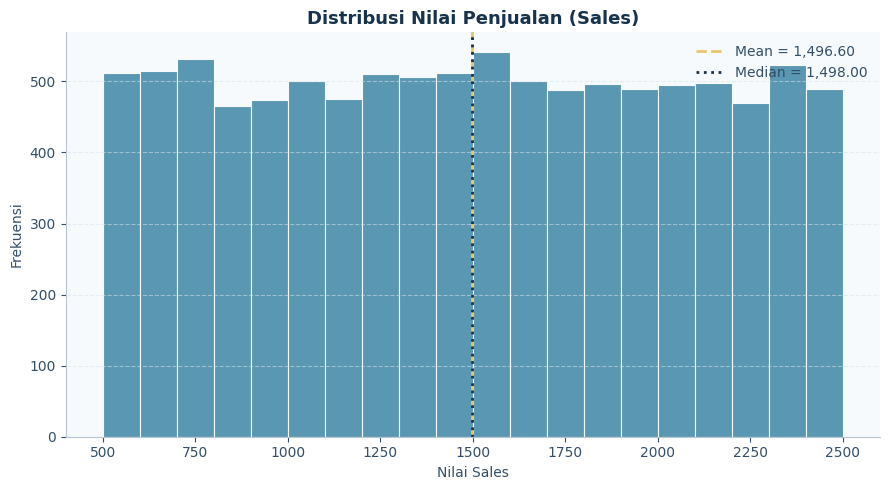

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    df['Sales'], bins=20, color=WARNA_VARIABEL['Sales'],
    edgecolor='white', linewidth=0.8, alpha=0.92
)
ax.axvline(df['Sales'].mean(), color=GOLD, linestyle='--', linewidth=2,
           label=f"Mean = {df['Sales'].mean():,.2f}")
ax.axvline(df['Sales'].median(), color=NAVY, linestyle=':', linewidth=2,
           label=f"Median = {df['Sales'].median():,.2f}")
ax.set_title('Distribusi Nilai Penjualan (Sales)')
ax.set_xlabel('Nilai Sales')
ax.set_ylabel('Frekuensi')
ax.legend()
rapikan_axes(ax)
plt.tight_layout()
plt.show()


### 6.2 Histogram Distribusi Discount

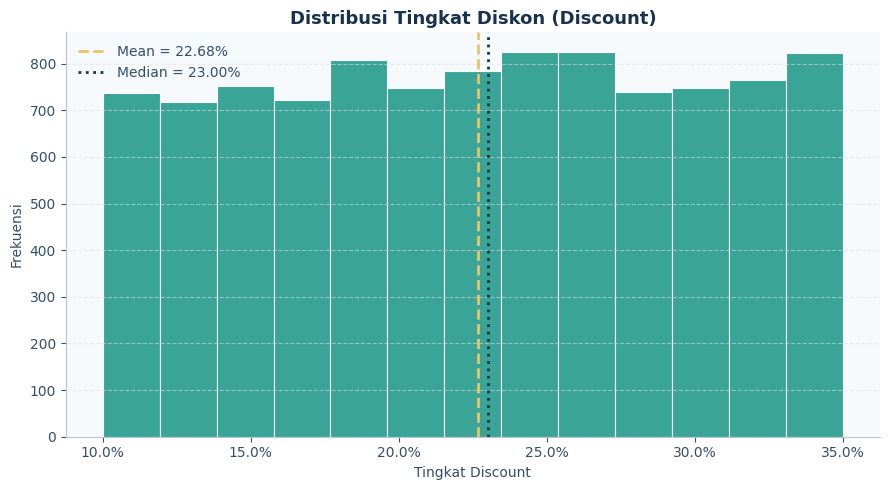

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    df['Discount'], bins=13, color=WARNA_VARIABEL['Discount'],
    edgecolor='white', linewidth=0.8, alpha=0.92
)
ax.axvline(df['Discount'].mean(), color=GOLD, linestyle='--', linewidth=2,
           label=f"Mean = {df['Discount'].mean():.2%}")
ax.axvline(df['Discount'].median(), color=NAVY, linestyle=':', linewidth=2,
           label=f"Median = {df['Discount'].median():.2%}")
ax.set_title('Distribusi Tingkat Diskon (Discount)')
ax.set_xlabel('Tingkat Discount')
ax.set_ylabel('Frekuensi')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()
rapikan_axes(ax)
plt.tight_layout()
plt.show()


### 6.3 Histogram Distribusi Profit

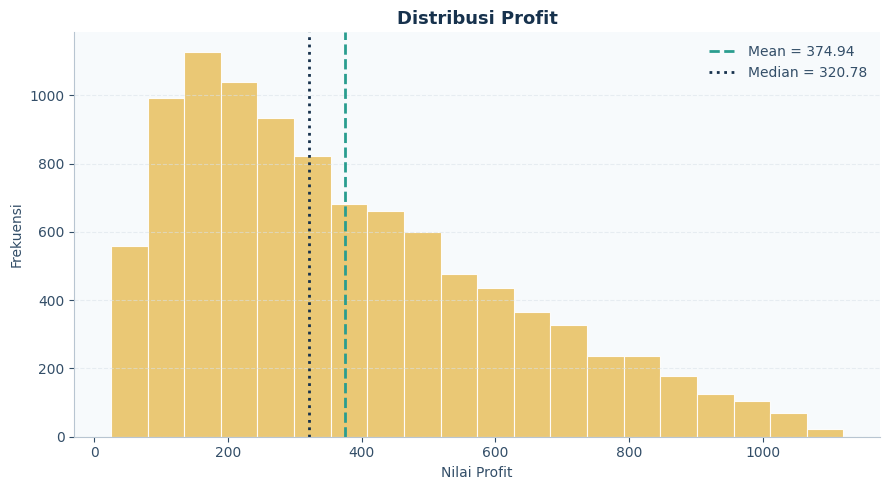

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    df['Profit'], bins=20, color=WARNA_VARIABEL['Profit'],
    edgecolor='white', linewidth=0.8, alpha=0.92
)
ax.axvline(df['Profit'].mean(), color=TEAL, linestyle='--', linewidth=2,
           label=f"Mean = {df['Profit'].mean():,.2f}")
ax.axvline(df['Profit'].median(), color=NAVY, linestyle=':', linewidth=2,
           label=f"Median = {df['Profit'].median():,.2f}")
ax.set_title('Distribusi Profit')
ax.set_xlabel('Nilai Profit')
ax.set_ylabel('Frekuensi')
ax.legend()
rapikan_axes(ax)
plt.tight_layout()
plt.show()


### 6.4 Interpretasi Histogram Berdasarkan Hasil Perhitungan

In [ ]:
print('INTERPRETASI RM 2 — POLA DISTRIBUSI')
sales_mean, sales_med = df['Sales'].mean(), df['Sales'].median()
disc_mean, disc_med = df['Discount'].mean(), df['Discount'].median()
profit_mean, profit_med = df['Profit'].mean(), df['Profit'].median()
print(f'1. Sales: mean {format_id(sales_mean)} dan median {format_id(sales_med)} berdekatan. Rentang nilai {format_id(df["Sales"].min())}–{format_id(df["Sales"].max())}. Histogram tersebar relatif merata pada rentang yang diamati.')
print(f'2. Discount: mean {disc_mean:.2%}, median {disc_med:.2%}; rentang {df["Discount"].min():.0%}–{df["Discount"].max():.0%}. Distribusinya mencakup berbagai tingkat diskon, tanpa satu rentang sempit yang mendominasi keseluruhan.')
print(f'3. Profit: mean {format_id(profit_mean)} lebih besar dari median {format_id(profit_med)}. Histogram menunjukkan lebih banyak transaksi pada Profit rendah–menengah dan frekuensi menurun ke nilai yang lebih tinggi.')
print('Keseluruhan: ini hanya interpretasi distribusi pada data, bukan pengujian hipotesis atau hubungan sebab-akibat.')

INTERPRETASI RM 2 — POLA DISTRIBUSI
1. Sales: mean 1.496,60 dan median 1.498,00 berdekatan. Rentang nilai 500,00–2.500,00. Histogram tersebar relatif merata pada rentang yang diamati.
2. Discount: mean 22.68%, median 23.00%; rentang 10%–35%. Distribusinya mencakup berbagai tingkat diskon, tanpa satu rentang sempit yang mendominasi keseluruhan.
3. Profit: mean 374,94 lebih besar dari median 320,78. Histogram menunjukkan lebih banyak transaksi pada Profit rendah–menengah dan frekuensi menurun ke nilai yang lebih tinggi.
Keseluruhan: ini hanya interpretasi distribusi pada data, bukan pengujian hipotesis atau hubungan sebab-akibat.


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">7. RM 3 — Analisis Deskriptif Berdasarkan Category</h2>

Setiap variabel dihitung lagi **di dalam masing-masing Category**: jumlah transaksi, mean, median, dan standar deviasi sampel. Analisis menggunakan nilai transaksi asli tanpa pembulatan untuk perhitungan.

Mean per kategori \(k\):

$$\bar{x}_k=\frac{\sum_{i=1}^{n_k}x_{ik}}{n_k}$$

Median per kategori ditentukan dari nilai \(x_{ik}\) yang **diurutkan dalam kategori tersebut** dengan aturan median ganjil/genap di atas.

Standar deviasi sampel per kategori:

$$s_k=\sqrt{\frac{\sum_{i=1}^{n_k}(x_{ik}-\bar{x}_k)^2}{n_k-1}}$$

\(n_k\) adalah jumlah transaksi pada Category ke-\(k\), dan \(x_{ik}\) adalah nilai variabel pada transaksi ke-\(i\) dalam kategori tersebut.

In [ ]:
ringkasan_category = (
    df.groupby('Category', sort=True)
      .agg(
        N=('Order ID', 'size'),
        Mean_Sales=('Sales','mean'),
        Median_Sales=('Sales','median'),
        SD_Sales=('Sales','std'),
        Mean_Discount=('Discount','mean'),
        Median_Discount=('Discount','median'),
        SD_Discount=('Discount','std'),
        Mean_Profit=('Profit','mean'),
        Median_Profit=('Profit','median'),
        SD_Profit=('Profit','std')
      )
      .reset_index()
)
assert ringkasan_category['N'].sum() == len(df), 'Jumlah transaksi antar Category tidak sesuai total dataset.'
print(f'Jumlah Category: {len(ringkasan_category)}; jumlah transaksi seluruh kategori: {ringkasan_category["N"].sum():,}')

Jumlah Category: 7; jumlah transaksi seluruh kategori: 9,994


### 7.1 Ringkasan Jumlah Transaksi dan Mean per Category (Tabel 4.4)

In [ ]:
tabel_ringkas = ringkasan_category[['Category','N','Mean_Sales','Mean_Discount','Mean_Profit']].copy()
tabel_ringkas['Mean_Discount'] *= 100
tabel_ringkas = tabel_ringkas.rename(columns={
    'N':'Jumlah Transaksi',
    'Mean_Sales':'Mean Sales',
    'Mean_Discount':'Mean Discount (%)',
    'Mean_Profit':'Mean Profit'
})
display(tampil_tabel(tabel_ringkas, caption='Tabel 4.4 - Statistik Deskriptif Berdasarkan Category',
    format_dict={'Jumlah Transaksi':'{:,.0f}', 'Mean Sales':'{:,.2f}',
                 'Mean Discount (%)':'{:.2f}%', 'Mean Profit':'{:,.2f}'}))

,Category,Jumlah Transaksi,Mean Sales,Mean Discount (%),Mean Profit
0,Bakery,"1,413","1,494.89",22.54%,374.04
1,Beverages,"1,400","1,489.51",23.03%,375.43
2,"Eggs, Meat & Fish","1,490","1,521.75",22.78%,380.78
3,Food Grains,"1,398","1,513.07",22.85%,378.51
4,Fruits & Veggies,"1,418","1,481.47",22.93%,374.05
5,Oil & Masala,"1,361","1,497.75",22.45%,365.83
6,Snacks,"1,514","1,477.90",22.20%,375.28


### 7.2 Mean, Median, dan Standar Deviasi Sales per Category (Tabel 4.5)

In [ ]:
tabel_sales = ringkasan_category[['Category','N','Mean_Sales','Median_Sales','SD_Sales']].copy()
tabel_sales.columns = ['Category','N','Mean Sales','Median Sales','SD Sales']
display(tampil_tabel(tabel_sales, caption='Tabel 4.5 - Mean, Median, dan Standar Deviasi Sales per Category',
  format_dict={'N':'{:,.0f}', 'Mean Sales':'{:,.2f}', 'Median Sales':'{:,.2f}', 'SD Sales':'{:,.2f}'}))

,Category,N,Mean Sales,Median Sales,SD Sales
0,Bakery,"1,413","1,494.89","1,501.00",580.83
1,Beverages,"1,400","1,489.51","1,512.00",585.20
2,"Eggs, Meat & Fish","1,490","1,521.75","1,522.00",572.85
3,Food Grains,"1,398","1,513.07","1,541.50",569.73
4,Fruits & Veggies,"1,418","1,481.47","1,450.00",574.53
5,Oil & Masala,"1,361","1,497.75","1,495.00",585.12
6,Snacks,"1,514","1,477.90","1,460.00",575.02


### 7.3 Mean, Median, dan Standar Deviasi Profit per Category (Tabel 4.6)

In [ ]:
tabel_profit = ringkasan_category[['Category','N','Mean_Profit','Median_Profit','SD_Profit']].copy()
tabel_profit.columns = ['Category','N','Mean Profit','Median Profit','SD Profit']
display(tampil_tabel(tabel_profit, caption='Tabel 4.6 - Mean, Median, dan Standar Deviasi Profit per Category',
  format_dict={'N':'{:,.0f}', 'Mean Profit':'{:,.2f}', 'Median Profit':'{:,.2f}', 'SD Profit':'{:,.2f}'}))

,Category,N,Mean Profit,Median Profit,SD Profit
0,Bakery,"1,413",374.04,313.28,242.52
1,Beverages,"1,400",375.43,326.63,235.74
2,"Eggs, Meat & Fish","1,490",380.78,331.50,243.97
3,Food Grains,"1,398",378.51,318.30,244.59
4,Fruits & Veggies,"1,418",374.05,327.51,234.98
5,Oil & Masala,"1,361",365.83,309.12,238.79
6,Snacks,"1,514",375.28,317.60,238.84


### 7.4 Mean, Median, dan Standar Deviasi Discount per Category (Tabel 4.7)

In [ ]:
tabel_discount = ringkasan_category[['Category','N','Mean_Discount','Median_Discount','SD_Discount']].copy()
for kolom in ['Mean_Discount','Median_Discount','SD_Discount']:
    tabel_discount[kolom] *= 100
tabel_discount.columns = ['Category','N','Mean Discount (%)','Median Discount (%)','SD Discount (pp)']
display(tampil_tabel(tabel_discount, caption='Tabel 4.7 - Mean, Median, dan Standar Deviasi Discount per Category',
  format_dict={'N':'{:,.0f}', 'Mean Discount (%)':'{:.2f}%', 'Median Discount (%)':'{:.2f}%', 'SD Discount (pp)':'{:.2f}'}))

,Category,N,Mean Discount (%),Median Discount (%),SD Discount (pp)
0,Bakery,"1,413",22.54%,23.00%,7.30
1,Beverages,"1,400",23.03%,23.00%,7.54
2,"Eggs, Meat & Fish","1,490",22.78%,23.00%,7.23
3,Food Grains,"1,398",22.85%,23.00%,7.49
4,Fruits & Veggies,"1,418",22.93%,23.00%,7.65
5,Oil & Masala,"1,361",22.45%,23.00%,7.54
6,Snacks,"1,514",22.20%,22.00%,7.48


### 7.5 Diagram Batang Mean per Category

Tiga grafik berikut mempertahankan visualisasi mean yang tercantum pada laporan. Perbandingan **median dan standar deviasi** diperlihatkan pada tabel 4.5–4.7 dan diterangkan pada interpretasi bagian 7.6.

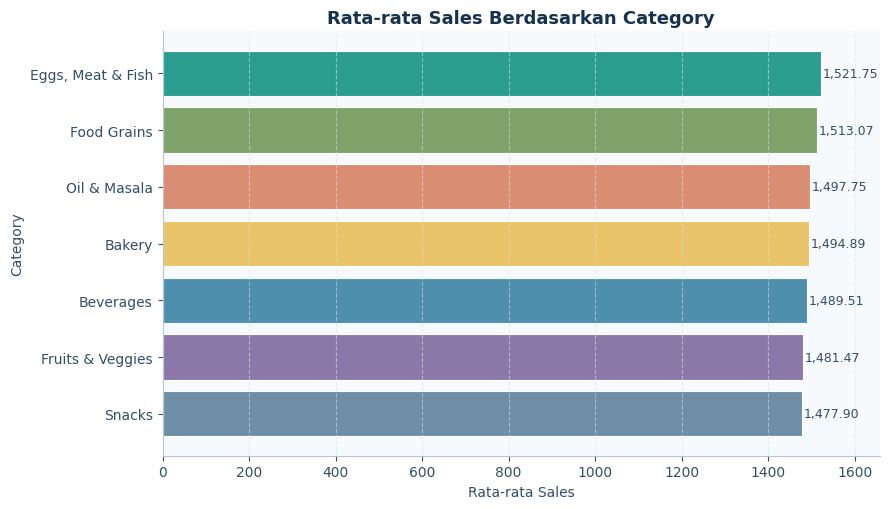

In [ ]:
grafik_sales = ringkasan_category.sort_values('Mean_Sales')
warna_bar = [WARNA_KATEGORI[k] for k in grafik_sales['Category']]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(
    grafik_sales['Category'], grafik_sales['Mean_Sales'],
    color=warna_bar, edgecolor='white', linewidth=0.8
)
ax.set_title('Rata-rata Sales Berdasarkan Category')
ax.set_xlabel('Rata-rata Sales')
ax.set_ylabel('Category')
ax.grid(True, axis='x', zorder=0)
ax.grid(False, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for bar, nilai in zip(bars, grafik_sales['Mean_Sales']):
    ax.text(nilai + 4, bar.get_y() + bar.get_height()/2, f'{nilai:,.2f}',
            va='center', fontsize=9, color=TEXT)

ax.set_xlim(0, grafik_sales['Mean_Sales'].max() * 1.09)
plt.tight_layout()
plt.show()

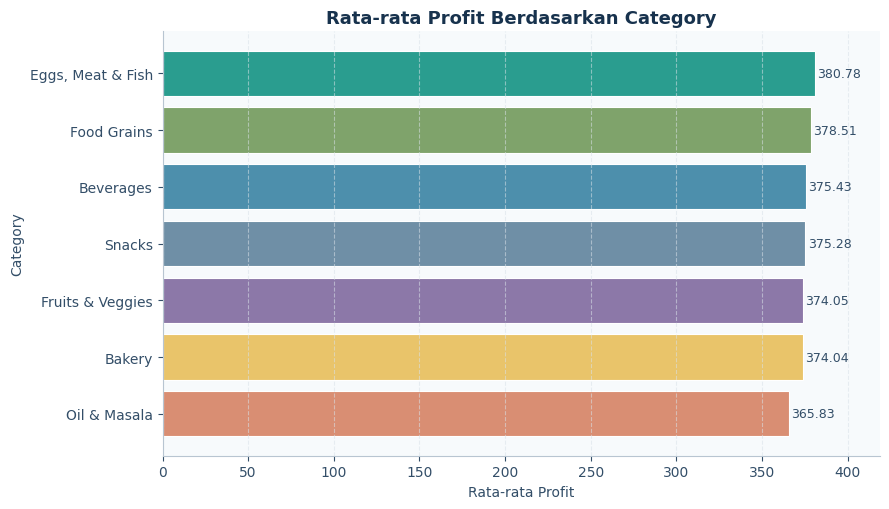

In [ ]:
grafik_profit = ringkasan_category.sort_values('Mean_Profit')
warna_bar = [WARNA_KATEGORI[k] for k in grafik_profit['Category']]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(
    grafik_profit['Category'], grafik_profit['Mean_Profit'],
    color=warna_bar, edgecolor='white', linewidth=0.8
)
ax.set_title('Rata-rata Profit Berdasarkan Category')
ax.set_xlabel('Rata-rata Profit')
ax.set_ylabel('Category')
ax.grid(True, axis='x', zorder=0)
ax.grid(False, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for bar, nilai in zip(bars, grafik_profit['Mean_Profit']):
    ax.text(nilai + 1.3, bar.get_y() + bar.get_height()/2, f'{nilai:,.2f}',
            va='center', fontsize=9, color=TEXT)

ax.set_xlim(0, grafik_profit['Mean_Profit'].max() * 1.10)
plt.tight_layout()
plt.show()

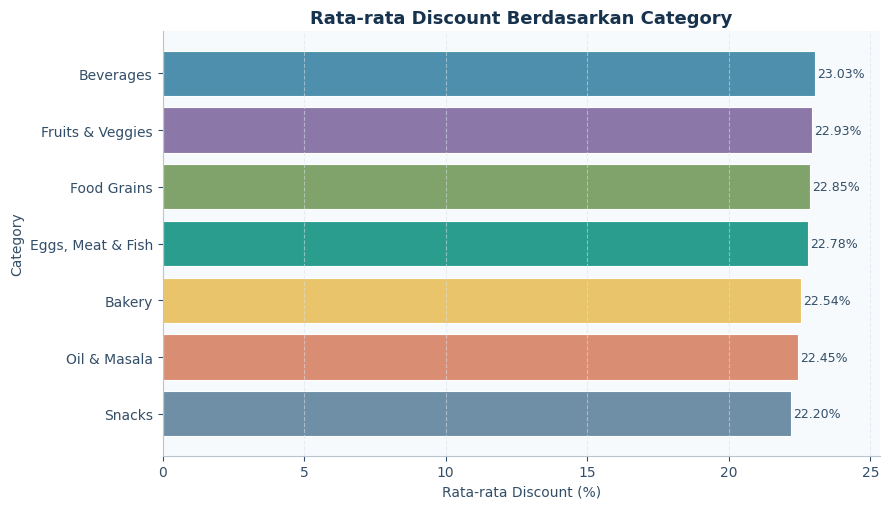

In [ ]:
grafik_discount = ringkasan_category.assign(**{'Mean_Discount (%)': ringkasan_category['Mean_Discount']*100}).sort_values('Mean_Discount (%)')
warna_bar = [WARNA_KATEGORI[k] for k in grafik_discount['Category']]

fig, ax = plt.subplots(figsize=(9, 5.2))
bars = ax.barh(
    grafik_discount['Category'], grafik_discount['Mean_Discount (%)'],
    color=warna_bar, edgecolor='white', linewidth=0.8
)
ax.set_title('Rata-rata Discount Berdasarkan Category')
ax.set_xlabel('Rata-rata Discount (%)')
ax.set_ylabel('Category')
ax.grid(True, axis='x', zorder=0)
ax.grid(False, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for bar, nilai in zip(bars, grafik_discount['Mean_Discount (%)']):
    ax.text(nilai + 0.08, bar.get_y() + bar.get_height()/2, f'{nilai:.2f}%',
            va='center', fontsize=9, color=TEXT)

ax.set_xlim(0, grafik_discount['Mean_Discount (%)'].max() * 1.10)
plt.tight_layout()
plt.show()

### 7.6 Pembahasan Perbandingan Mean, Median, dan Standar Deviasi

In [ ]:
# Identifikasi semua hasil ekstrem langsung dari data agregat (tanpa input manual).
def ekstrem(nama_kolom, mode='max'):
    idx = ringkasan_category[nama_kolom].idxmax() if mode == 'max' else ringkasan_category[nama_kolom].idxmin()
    row = ringkasan_category.loc[idx]
    return row['Category'], row[nama_kolom]

print('HASIL PERBANDINGAN PER CATEGORY — RM 3')
for col, label, pct in [
  ('Mean_Sales', 'Mean Sales', False), ('Median_Sales', 'Median Sales', False), ('SD_Sales', 'SD Sales', False),
  ('Mean_Profit', 'Mean Profit', False), ('Median_Profit', 'Median Profit', False), ('SD_Profit', 'SD Profit', False),
  ('Mean_Discount', 'Mean Discount', True), ('Median_Discount', 'Median Discount', True), ('SD_Discount', 'SD Discount', True)
]:
    kat_max, v_max = ekstrem(col)
    kat_min, v_min = ekstrem(col, 'min')
    f = (lambda v: f'{v:.2%}') if pct and not col.startswith('SD_') else ((lambda v: f'{v*100:.2f} pp') if pct else (lambda v: format_id(v)))
    print(f'{label:18}: tertinggi = {kat_max} ({f(v_max)}); terendah = {kat_min} ({f(v_min)})')

print('\nInterpretasi utama:')
print('• Mean Sales tertinggi pada Eggs, Meat & Fish, tetapi median Sales tertinggi pada Food Grains.')
print('• Mean dan median Profit tertinggi pada Eggs, Meat & Fish; keduanya terendah pada Oil & Masala.')
print('• Mean Discount tertinggi pada Beverages; SD per kategori menunjukkan keragaman tingkat Discount.')
print('• Kategori dengan SD lebih tinggi mempunyai variasi nilai transaksi lebih besar pada skala variabel yang sama.')
print('• Semua ini adalah perbandingan deskriptif; tidak menguji signifikansi atau sebab-akibat.')

HASIL PERBANDINGAN PER CATEGORY — RM 3
Mean Sales        : tertinggi = Eggs, Meat & Fish (1.521,75); terendah = Snacks (1.477,90)
Median Sales      : tertinggi = Food Grains (1.541,50); terendah = Fruits & Veggies (1.450,00)
SD Sales          : tertinggi = Beverages (585,20); terendah = Food Grains (569,73)
Mean Profit       : tertinggi = Eggs, Meat & Fish (380,78); terendah = Oil & Masala (365,83)
Median Profit     : tertinggi = Eggs, Meat & Fish (331,50); terendah = Oil & Masala (309,12)
SD Profit         : tertinggi = Food Grains (244,59); terendah = Fruits & Veggies (234,98)
Mean Discount     : tertinggi = Beverages (23.03%); terendah = Snacks (22.20%)
Median Discount   : tertinggi = Bakery (23.00%); terendah = Snacks (22.00%)
SD Discount       : tertinggi = Fruits & Veggies (7.65 pp); terendah = Eggs, Meat & Fish (7.23 pp)

Interpretasi utama:
• Mean Sales tertinggi pada Eggs, Meat & Fish, tetapi median Sales tertinggi pada Food Grains.
• Mean dan median Profit tertinggi pada Eggs

<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">8. Ringkasan Jawaban Tiga Rumusan Masalah</h2>

In [ ]:
mean_sales_cat, nilai_mean_sales_cat = ekstrem('Mean_Sales')
median_sales_cat, nilai_median_sales_cat = ekstrem('Median_Sales')
mean_profit_cat, nilai_mean_profit_cat = ekstrem('Mean_Profit')
mean_discount_cat, nilai_mean_discount_cat = ekstrem('Mean_Discount')

ringkasan_hasil = pd.DataFrame({
    'Rumusan Masalah': [
      'RM 1 - Karakteristik Sales, Discount, dan Profit',
      'RM 2 - Pola distribusi tiga variabel',
      'RM 3 - Perbandingan deskriptif berdasarkan Category'
    ],
    'Ringkasan Hasil': [
      f'Mean Sales {format_id(df["Sales"].mean())}, median {format_id(df["Sales"].median())}; '
      f'mean Discount {df["Discount"].mean():.2%}, median {df["Discount"].median():.2%}; '
      f'mean Profit {format_id(df["Profit"].mean())}, median {format_id(df["Profit"].median())}.',
      'Sales dan Discount: mean dekat dengan median; Profit: mean lebih besar dari median dan histogram '
      'lebih banyak pada nilai rendah–menengah.',
      f'Mean Sales dan Profit tertinggi pada {mean_sales_cat}; mean Discount tertinggi pada {mean_discount_cat}. '
      f'Median Sales tertinggi pada {median_sales_cat} ({format_id(nilai_median_sales_cat)}). '
      'Ketiga variabel juga dibandingkan berdasarkan standar deviasi per Category.'
    ]
})
display(tampil_tabel(ringkasan_hasil, caption='Ringkasan Jawaban Rumusan Masalah (sesuai BAB 4.6)'))

,Rumusan Masalah,Ringkasan Hasil
0,"RM 1 - Karakteristik Sales, Discount, dan Profit","Mean Sales 1.496,60, median 1.498,00; mean Discount 22.68%, median 23.00%; mean Profit 374,94, median 320,78."
1,RM 2 - Pola distribusi tiga variabel,Sales dan Discount: mean dekat dengan median; Profit: mean lebih besar dari median dan histogram lebih banyak pada nilai rendah–menengah.
2,RM 3 - Perbandingan deskriptif berdasarkan Category,"Mean Sales dan Profit tertinggi pada Eggs, Meat & Fish; mean Discount tertinggi pada Beverages. Median Sales tertinggi pada Food Grains (1.541,50). Ketiga variabel juga dibandingkan berdasarkan standar deviasi per Category."


<h2 style="color:#17324D;border-bottom:2px solid #2A9D8F;">9. Kesimpulan dan Pemeriksaan Konsistensi Output</h2>

1. **RM 1:** Statistik deskriptif terhadap 9.994 transaksi menggambarkan ukuran pemusatan dan penyebaran Sales, Discount, dan Profit.
2. **RM 2:** Histogram memperlihatkan Sales dan Discount tersebar di berbagai rentang nilai; Profit lebih sering berada pada nilai rendah–menengah. Rata-rata Profit lebih tinggi daripada mediannya.
3. **RM 3:** Perbandingan antar tujuh Category tidak hanya menggunakan rata-rata, tetapi juga median dan standar deviasi. Mean Sales dan Profit tertinggi ada pada Eggs, Meat & Fish, sementara median Sales tertinggi ada pada Food Grains dan mean Discount tertinggi ada pada Beverages.

**Batas interpretasi:** Hasil ini hanya menggambarkan dataset yang dianalisis. Tidak ada uji statistik inferensial, klaim pengaruh, atau kesimpulan sebab-akibat.

In [ ]:
# Validasi angka kunci yang tercantum dalam laporan PA revisi.
cek_konsistensi = {
    'Jumlah transaksi = 9.994': len(df) == 9994,
    'Jumlah variabel asli = 11': df.shape[1] == 11,
    'Jumlah Category = 7': df['Category'].nunique() == 7,
    'Mean Sales = 1496.60': round(df['Sales'].mean(), 2) == 1496.60,
    'Median Sales = 1498.00': round(df['Sales'].median(), 2) == 1498.00,
    'Mean Discount = 22.68%': round(df['Discount'].mean()*100, 2) == 22.68,
    'Median Discount = 23.00%': round(df['Discount'].median()*100, 2) == 23.00,
    'Mean Profit = 374.94': round(df['Profit'].mean(), 2) == 374.94,
    'Median Profit = 320.78': round(df['Profit'].median(), 2) == 320.78,
    'Mean Sales tertinggi = Eggs, Meat & Fish': ekstrem('Mean_Sales')[0] == 'Eggs, Meat & Fish',
    'Median Sales tertinggi = Food Grains': ekstrem('Median_Sales')[0] == 'Food Grains',
    'Mean Profit tertinggi = Eggs, Meat & Fish': ekstrem('Mean_Profit')[0] == 'Eggs, Meat & Fish',
    'Mean Discount tertinggi = Beverages': ekstrem('Mean_Discount')[0] == 'Beverages'
}
for k, valid in cek_konsistensi.items():
    print(('OK' if valid else 'PERLU DIPERIKSA'), '-', k)
assert all(cek_konsistensi.values()), 'Ada hasil yang tidak sama dengan laporan revisi.'
print('\nSELESAI: seluruh angka kunci konsisten dengan laporan PA revisi.')

OK - Jumlah transaksi = 9.994
OK - Jumlah variabel asli = 11
OK - Jumlah Category = 7
OK - Mean Sales = 1496.60
OK - Median Sales = 1498.00
OK - Mean Discount = 22.68%
OK - Median Discount = 23.00%
OK - Mean Profit = 374.94
OK - Median Profit = 320.78
OK - Mean Sales tertinggi = Eggs, Meat & Fish
OK - Median Sales tertinggi = Food Grains
OK - Mean Profit tertinggi = Eggs, Meat & Fish
OK - Mean Discount tertinggi = Beverages

SELESAI: seluruh angka kunci konsisten dengan laporan PA revisi.
